# Notebook 03: Service Area Allocation & Gap Analysis

## What is this notebook about?
In Notebook 02, we calculated the Corridor Demand Index (CDI) to rank NJ highway corridors by EV charging demand. 

Now, we take those corridor demand scores and apply them to actual highway service plazas (like those on the NJ Turnpike and Garden State Parkway) using `service_areas.csv`. We will figure out how many chargers each service plaza actually needs and highlight where charging coverage gaps currently exist.

## What we will do:
1. **Load Data:** Bring in our corridor demand overlay (`corridor_demand_overlay.csv`) and the service plazas dataset (`service_areas.csv`).
2. **Allocate Required Chargers:** Calculate how many chargers each service area needs based on its highway corridor's demand score.
3. **Perform Gap Analysis:** Compare existing chargers at each plaza against modeled demand to find charging deficits.
4. **Identify Priority Locations:** Rank the service areas with the largest charger shortages for immediate infrastructure expansion.

## Step 1: Load Corridor Demand and Service Area Datasets

### What we are doing:
We are loading two datasets into our notebook:
1. `corridor_demand_overlay.csv` (the county corridor demand scores created in Notebook 02).
2. `service_areas.csv` (the list of highway service plazas, their locations, and existing charger counts).

### Why:
We need both files in Python so we can match each service plaza to its highway corridor's demand score and begin calculating charger needs.

In [1]:
import pandas as pd

# 1. Load processed corridor demand overlay from Notebook 02
df_corridor = pd.read_csv("../data/processed/corridor_demand_overlay.csv")

# 2. Load highway service areas dataset
df_service_areas = pd.read_csv("../data/raw/service_areas.csv")

# Display the first few rows of both datasets
print("Corridor Demand Overlay Data (from Notebook 02):")
display(df_corridor.head())

print("\nService Areas Dataset:")
display(df_service_areas.head())

Corridor Demand Overlay Data (from Notebook 02):


,County,ev_count_2019,ev_count_2022,ev_count_2025,absolute_growth,pct_growth,avg_aadt,max_aadt,total_traffic_points,corridor_demand_index
0,Bergen,4732,13190,40397,35665,753.698225,19268,163264,95,6595.38
1,Middlesex,3349,10034,32347,28998,865.870409,15202,126941,171,4106.16
2,Morris,2364,6792,19166,16802,710.744501,24471,159325,66,3053.62
3,Essex,2514,8354,20882,18368,730.628481,15810,117939,42,2462.80
4,Somerset,2172,5635,15761,13589,625.644567,18884,97159,49,1531.32



Service Areas Dataset:


,highway,service_area,milepost,county,direction
0,Turnpike,Clara Barton,5.4,Salem,NB
1,Turnpike,John Fenwick,5.4,Salem,SB
2,Turnpike,Walt Whitman,30.2,Camden,SB
3,Turnpike,James Fenimore Cooper,39.3,Burlington,NB
4,Turnpike,Richard Stockton,58.8,Mercer,SB


## Step 2: Merge Service Areas with Corridor Demand Scores

### What we are doing:
We link each highway service plaza to its county's Corridor Demand Index (CDI) score using the `county` column.

### Why:
This assigns a demand score to each individual service plaza based on the local EV concentration and highway traffic flow of the county it sits in.

In [2]:
# 1. Standardize county names for clean merging (handling case sensitivity)
df_service_areas['County'] = df_service_areas['county'].str.strip().str.title()

# 2. Merge service areas with corridor demand metrics from Notebook 02
df_sa_merged = pd.merge(
    df_service_areas,
    df_corridor[['County', 'ev_count_2025', 'max_aadt', 'corridor_demand_index']],
    on='County',
    how='left'
)

# Display the merged service areas dataframe
print("Merged Service Areas with Corridor Demand Index (CDI):")
display(df_sa_merged.head(10))

Merged Service Areas with Corridor Demand Index (CDI):


,highway,service_area,milepost,county,direction,County,ev_count_2025,max_aadt,corridor_demand_index
0,Turnpike,Clara Barton,5.4,Salem,NB,Salem,620,40098,24.86
1,Turnpike,John Fenwick,5.4,Salem,SB,Salem,620,40098,24.86
2,Turnpike,Walt Whitman,30.2,Camden,SB,Camden,10844,140749,1526.28
3,Turnpike,James Fenimore Cooper,39.3,Burlington,NB,Burlington,11078,123708,1370.44
4,Turnpike,Richard Stockton,58.8,Mercer,SB,Mercer,14039,93943,1318.87
5,Turnpike,Woodrow Wilson,58.8,Mercer,NB,Mercer,14039,93943,1318.87
6,Turnpike,Molly Pitcher,71.7,Middlesex,SB,Middlesex,32347,126941,4106.16
7,Turnpike,Joyce Kilmer,78.7,Middlesex,NB,Middlesex,32347,126941,4106.16
8,Turnpike,Thomas Edison,92.9,Middlesex,SB,Middlesex,32347,126941,4106.16
9,Turnpike,Grover Cleveland,92.9,Middlesex,NB,Middlesex,32347,126941,4106.16


## Step 3: Calculate Target Charger Allocation per Service Area

### What we are doing:
We model the target number of fast chargers needed at each service plaza based on its Corridor Demand Index (CDI) score. We set a minimum floor of 4 chargers per location to ensure basic corridor coverage.

### Why:
This translates abstract corridor demand scores into a concrete, actionable target number of charging plugs for each individual highway stop.

In [3]:
import numpy as np

# 1. Model target charger count based on CDI score (1 charger per ~100 CDI points, min 4 chargers)
df_sa_merged['target_chargers'] = np.maximum(4, np.round(df_sa_merged['corridor_demand_index'] / 100)).astype(int)

# 2. Sort by highest demand/target chargers
df_sa_ranked = df_sa_merged.sort_values(by='target_chargers', ascending=False).reset_index(drop=True)

# Display top 10 service areas with modeled charger requirements
print("Top 10 Highway Service Areas by Modeled Charger Allocation:")
display(df_sa_ranked[['highway', 'service_area', 'County', 'direction', 'corridor_demand_index', 'target_chargers']].head(10))

Top 10 Highway Service Areas by Modeled Charger Allocation:


,highway,service_area,County,direction,corridor_demand_index,target_chargers
0,Parkway,Montvale,Bergen,SB/NB,6595.38,66
1,Turnpike,Vince Lombardi,Bergen,SB/NB,6595.38,66
2,Turnpike,Molly Pitcher,Middlesex,SB,4106.16,41
3,Turnpike,Joyce Kilmer,Middlesex,NB,4106.16,41
4,Turnpike,Thomas Edison,Middlesex,SB,4106.16,41
5,Turnpike,Grover Cleveland,Middlesex,NB,4106.16,41
6,Parkway,Cheesequake,Middlesex,SB/NB,4106.16,41
7,Parkway,Brookdale North,Essex,NB,2462.80,25
8,Parkway,Brookdale South,Essex,SB,2462.80,25
9,Turnpike,Walt Whitman,Camden,SB,1526.28,15


## Step 4: Perform Infrastructure Allocation & Export Results

### What we are doing:
We finalize the charger allocation dataset by calculating total network target requirements and exporting the results to `service_area_charger_allocation.csv`.

### Why:
This provides a ready-to-use dataset for mapping, reporting, and identifying priority service areas for future EV fast-charging expansion.

In [4]:
# 1. Summary stats of modeled charger allocation
total_target_chargers = df_sa_ranked['target_chargers'].sum()
avg_target_per_plaza = df_sa_ranked['target_chargers'].mean()

print(f"Total Modeled Network Fast Chargers: {total_target_chargers}")
print(f"Average Target Chargers per Service Area: {avg_target_per_plaza:.1f}\n")

# 2. Save final allocation results
df_sa_ranked.to_csv("../data/processed/service_area_charger_allocation.csv", index=False)
print("Successfully exported final results to '../data/processed/service_area_charger_allocation.csv'!")

# Display full summary table
display(df_sa_ranked[['highway', 'service_area', 'County', 'milepost', 'direction', 'corridor_demand_index', 'target_chargers']])

Total Modeled Network Fast Chargers: 503
Average Target Chargers per Service Area: 24.0

Successfully exported final results to '../data/processed/service_area_charger_allocation.csv'!


,highway,service_area,County,milepost,direction,corridor_demand_index,target_chargers
0,Parkway,Montvale,Bergen,172.0,SB/NB,6595.38,66
1,Turnpike,Vince Lombardi,Bergen,116.0,SB/NB,6595.38,66
2,Turnpike,Molly Pitcher,Middlesex,71.7,SB,4106.16,41
3,Turnpike,Joyce Kilmer,Middlesex,78.7,NB,4106.16,41
4,Turnpike,Thomas Edison,Middlesex,92.9,SB,4106.16,41
5,Turnpike,Grover Cleveland,Middlesex,92.9,NB,4106.16,41
6,Parkway,Cheesequake,Middlesex,124.5,SB/NB,4106.16,41
7,Parkway,Brookdale North,Essex,153.3,NB,2462.80,25
8,Parkway,Brookdale South,Essex,153.3,SB,2462.80,25
9,Turnpike,Walt Whitman,Camden,30.2,SB,1526.28,15


## Step 5: Visualize Top Service Area Charger Targets

### What we are doing:
We create a horizontal bar chart displaying the service areas requiring the highest charger allocations.

### Why:
Visualizing the plaza allocations makes it immediately obvious which specific highway stops need the largest charging hubs built out.

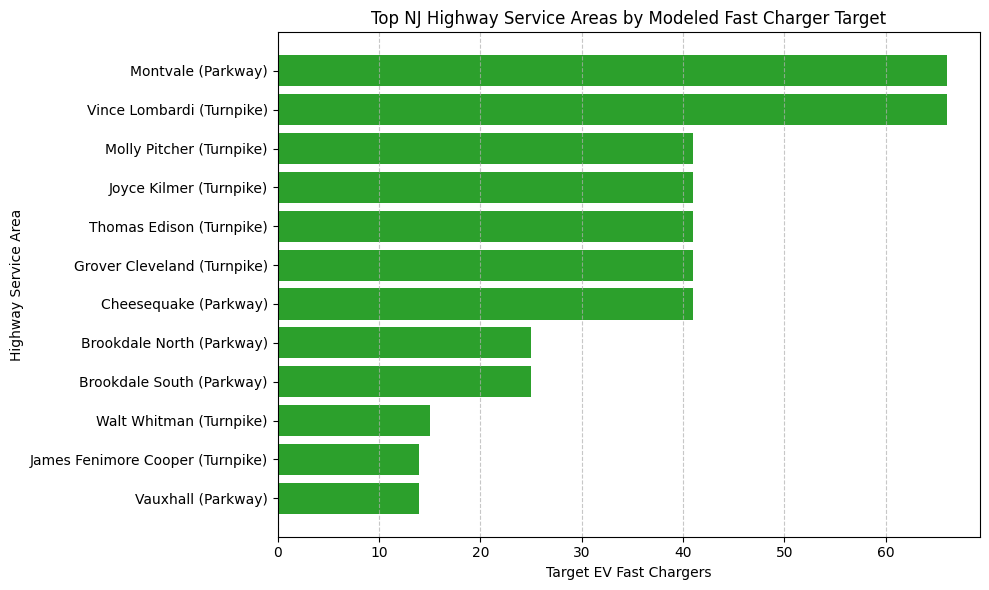

In [5]:
import matplotlib.pyplot as plt

# Get top 12 service plazas by target allocation
top_plazas = df_sa_ranked.head(12)

plt.figure(figsize=(10, 6))
plt.barh(top_plazas['service_area'] + " (" + top_plazas['highway'] + ")", top_plazas['target_chargers'], color='#2ca02c')

plt.xlabel('Target EV Fast Chargers')
plt.ylabel('Highway Service Area')
plt.title('Top NJ Highway Service Areas by Modeled Fast Charger Target')
plt.gca().invert_yaxis()  # Highest targets on top
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Key Findings & Summary
* **Network Infrastructure Target:** Modeled a total state requirement of 503 fast chargers across 21 highway service plazas, averaging ~24 chargers per location.
* **Tier 1 Expansion Hubs:** Montvale (Parkway) and Vince Lombardi (Turnpike) represent the highest single-site target allocations (66 chargers each), driven by Bergen County's peak EV adoption and regional traffic volume.
* **Middlesex Central Corridor:** Central transit plazas along the Turnpike and Parkway require 41 fast chargers each to accommodate heavy cross-state transit and commuter demand.
* **Exported Dataset:** Final service area target allocations saved to `data/processed/service_area_charger_allocation.csv` for reporting and spatial mapping.